<div style="width: 100%; overflow: hidden;">
    <div style="width: 150px; float: left;"> <img src="data/D4Sci_logo_ball.png" alt="Data For Science, Inc" align="left" border="0"> </div>
    <div style="float: left; margin-left: 10px;"> <h1>Harness Engineering</h1>
<h1>06 - Failure Handling and Fault Injection</h1>
        <p>Bruno Gonçalves<br/>
        <a href="http://www.data4sci.com/">www.data4sci.com</a><br/>
            @bgoncalves, @data4sci</p></div>
</div>

In [1]:
from collections import Counter
from pprint import pprint
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

import watermark

import subprocess
import sys
import time

from harness.mcp_client import MCPClient, MCPTimeout, MCPConnectionError, ToolResult
from harness.llm import MockAnalyst
from harness.agent import Agent, ToolBox
from harness.workshop import ensure, load, restore
from harness.exercises import show_run, check_06

%load_ext watermark
%matplotlib inline

We start by print out the versions of the libraries we're using for future reference

In [2]:
%watermark -n -v -m -g -iv

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.17.1

Compiler    : Clang 22.1.3 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 16
Architecture: 64bit

Git hash: f45998e2cfd5a6dc68ecdc40a669ed274dd25212

duckdb    : 1.5.6
json      : 2.0.9
matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.0
watermark : 2.6.0



Load default figure style

In [3]:
plt.style.use('d4sci.mplstyle')
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

This notebook builds on every module from notebooks 02-05. If you skipped any of them, the next cell restores the reference copy.

In [4]:
ensure("permissions", "context", "guardrails", "verify")
from harness.guardrails import locked_server_command

# Everything fails, eventually

So far our tools have always answered. In production they won't: servers hang, connections drop, responses come back malformed or enormous, and models get stuck retrying the same broken call. A harness has to decide, for **every** kind of failure, what happens next:

| Failure | Example | Response |
|:--|:--|:--|
| timeout | query never returns | stop waiting, restart the server, retry |
| transient | connection reset, lock contention | retry with backoff |
| crash | server process died | restart, retry |
| malformed | an HTML error page instead of JSON | treat as transient, retry |
| permanent | bad SQL, unknown table | **don't retry**: tell the model and let it re-plan |
| runaway | model loops on a failing call | budgets stop the run |

And every run leaves a **structured trace**, so we can tell afterwards which of these happened.

**You are building `harness/supervisor.py` in this notebook**, and at the end `harness/analyst.py`, which assembles the complete harness. Cells that start with `%%writefile` write the modules one section at a time (`-a` appends). Run them in order. Finished copies are in `reference/`; `restore("supervisor")` or `restore("analyst")` puts them back.

# 1. Classify before you react

Retrying a permanent error wastes budget, and giving up on a transient one throws away a run that could have succeeded. So the first step is classification:

In [5]:
%%writefile harness/supervisor.py
"""Run supervision: timeouts, retries, budgets, traces and fault injection.

``ResilientInvoker``  executes tool calls with a deadline, classified retries,
                      exponential backoff and server restarts
``Budget``            hard limits on steps, tool calls, tokens and wall-clock time
``Tracer``            structured, append-only run events (JSONL-ready)
``FaultInjector``     wraps an invoker and breaks it on purpose, deterministically
"""

from __future__ import annotations

import json
import random
import time
import uuid
from collections import Counter
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable

from .agent import BudgetExceeded
from .mcp_client import MCPClient, MCPConnectionError, MCPTimeout, ToolResult


# --- error classification --------------------------------------------------------------

TRANSIENT_MARKERS = ("io error", "could not set lock", "connection reset", "temporarily",
                     "try again", "503", "502", "rate limit")


def classify_failure(error: Exception | ToolResult) -> str:
    """timeout | transient | permanent. Only the first two are worth retrying."""
    if isinstance(error, MCPTimeout) or isinstance(error, TimeoutError):
        return "timeout"
    if isinstance(error, (MCPConnectionError, ConnectionError, BrokenPipeError)):
        return "transient"
    text = error.text if isinstance(error, ToolResult) else str(error)
    if any(m in text.lower() for m in TRANSIENT_MARKERS):
        return "transient"
    return "permanent"

Overwriting harness/supervisor.py


In [6]:
load("supervisor")
from harness.supervisor import classify_failure

examples = [MCPTimeout("tools/call timed out after 10s"),
            MCPConnectionError("pipe to MCP server broken"),
            ToolResult(False, "IO Error: Could not set lock on file"),
            ToolResult(False, 'Catalog Error: Table with name ordrs does not exist! Did you mean "orders"?'),
            ToolResult(False, "blocked by harness: Copy is not a read-only statement")]
for e in examples:
    print(f"{classify_failure(e):10} {getattr(e, 'text', None) or repr(e)}")

timeout    MCPTimeout('tools/call timed out after 10s')
transient  MCPConnectionError('pipe to MCP server broken')
transient  IO Error: Could not set lock on file
permanent  Catalog Error: Table with name ordrs does not exist! Did you mean "orders"?
permanent  blocked by harness: Copy is not a read-only statement


# 2. Timeouts: stop waiting, then clean up

Here is a real hang: a query against the real server that would take minutes. The client gives up after 2 seconds:

In [7]:
hung = MCPClient(timeout=2).start()
SLOW = "SELECT COUNT(*) FROM range(20000000000) t(i) WHERE i % 7 = 3"

t0 = time.perf_counter()
try:
    hung.call_tool("execute_query", {"sql": SLOW})
except MCPTimeout as e:
    print(f"{e}  ({time.perf_counter() - t0:.1f}s)")

tools/call timed out after 2s  (2.0s)


In [8]:
r = hung.call_tool("execute_query", {"sql": "SELECT 42 AS answer"})
print(r.ok, r.data["rows"])

True [[42]]


The server still answers new queries. So is everything fine? Let's look at how hard the server process is working:

In [9]:
def cpu_percent(proc):
    """CPU use of a process via `ps` (macOS/Linux)."""
    try:
        out = subprocess.run(["ps", "-o", "%cpu=", "-p", str(proc.pid)], capture_output=True, text=True)
        return float(out.stdout.strip())
    except (OSError, ValueError):
        return float("nan")

time.sleep(1)
print(f"server CPU after the timeout: {cpu_percent(hung.proc):.0f}%")

server CPU after the timeout: 197%


The abandoned query is **still running**, burning CPU and holding memory, and it will keep going until it finishes, minutes from now. A client-side timeout stops *waiting*; it doesn't stop the *work*. Do that a few times and the server falls over.

The reliable way to cancel is to restart the server. (The DuckDB server's own `--query-timeout` flag is a good second line of defense on the server side.)

In [10]:
hung.restart()
time.sleep(1)
print(f"server CPU after a restart: {cpu_percent(hung.proc):.0f}%")
print(hung.call_tool("execute_query", {"sql": "SELECT 42 AS answer"}).data["rows"])
hung.close()

server CPU after a restart: 2%
[[42]]


# 3. Retries with backoff, and fault injection

Before adding retries we need to be able to *see* them. A `Tracer` records structured events: one flat dictionary per event, timestamped from the start of the run. It plugs into the `tracer` hook of the `Agent`, and every other component can report to it too.

In [11]:
%%writefile -a harness/supervisor.py


# --- tracing -----------------------------------------------------------------------------

class Tracer:
    """Collects structured events; one dict per event, ready for JSONL or pandas."""

    def __init__(self, run_id: str | None = None):
        self.run_id = run_id or uuid.uuid4().hex[:8]
        self.t0 = time.perf_counter()
        self.events: list[dict] = []

    def emit(self, kind: str, **fields: Any) -> None:
        self.events.append({"run_id": self.run_id,
                            "t": round(time.perf_counter() - self.t0, 4),
                            "kind": kind, **fields})

    def to_jsonl(self, path: str | Path) -> Path:
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open("a") as f:
            for e in self.events:
                f.write(json.dumps(e, default=str) + "\n")
        return path

    def df(self):
        import pandas as pd
        return pd.DataFrame(self.events)

    def counts(self) -> Counter:
        return Counter(e["kind"] for e in self.events)

Appending to harness/supervisor.py


`ResilientInvoker` wraps every tool execution: deadline, classification, exponential backoff with jitter, and a restart after timeouts and crashes. Permanent errors go straight back to the caller. `ReplanAdvisor` is the matching `after_tool` hook: after repeated failures it tells the model to change course.

In [12]:
%%writefile -a harness/supervisor.py


# --- resilient execution ----------------------------------------------------------------------

class ResilientInvoker:
    """Execute a tool with a deadline, retry what is worth retrying, restart what is broken.

    Permanent errors (bad SQL, unknown table) are returned to the model at once:
    retrying them only wastes budget. The model re-plans instead."""

    def __init__(self, client: MCPClient, call: Callable[[str, dict], ToolResult] | None = None,
                 timeout: float = 10.0, max_retries: int = 2, backoff: float = 0.2,
                 tracer: Tracer | None = None, seed: int = 0):
        self.client = client
        client.timeout = timeout
        self.call = call or (lambda name, args: client.call_tool(name, args, timeout=self.timeout))
        self.timeout = timeout
        self.max_retries = max_retries
        self.backoff = backoff
        self.tracer = tracer
        self.rng = random.Random(seed)

    def _emit(self, kind: str, **f) -> None:
        if self.tracer:
            self.tracer.emit(kind, **f)

    def __call__(self, name: str, arguments: dict) -> ToolResult:
        last: Exception | ToolResult | None = None
        for attempt in range(self.max_retries + 1):
            if attempt:
                delay = self.backoff * 2 ** (attempt - 1) * (1 + self.rng.random() / 2)
                self._emit("retry", tool=name, attempt=attempt, delay=round(delay, 3),
                           cause=classify_failure(last))
                time.sleep(delay)
            try:
                if not self.client.alive:
                    self._emit("restart", reason="server not running")
                    self.client.restart()
                result = self.call(name, arguments)
            except Exception as e:  # noqa: BLE001
                kind = classify_failure(e)
                self._emit("tool_failure", tool=name, attempt=attempt, cls=kind,
                           error=f"{type(e).__name__}: {e}")
                last = e
                if kind == "permanent":
                    break
                if kind == "timeout":   # a hung server may never answer: start over
                    self._emit("restart", reason="timeout")
                    self.client.restart()
                continue
            if result.ok and result.data is None and result.text.lstrip()[:1] not in ("{", "["):
                last = ToolResult(False, f"malformed tool response: {result.text[:80]!r}")
                self._emit("tool_failure", tool=name, attempt=attempt, cls="transient",
                           error=last.text)
                continue
            if result.ok or classify_failure(result) == "permanent":
                return result
            self._emit("tool_failure", tool=name, attempt=attempt, cls="transient",
                       error=result.text[:200])
            last = result
        if isinstance(last, ToolResult):
            return ToolResult(False, f"{last.text} (gave up after {attempt + 1} attempts)")
        return ToolResult(False, f"{type(last).__name__}: {last} "
                                 f"(gave up after {attempt + 1} attempts)")


class ReplanAdvisor:
    """``after_tool`` hook: after repeated failures, tell the model to change course."""

    def __init__(self, threshold: int = 2):
        self.threshold = threshold
        self.consecutive = 0

    def __call__(self, call, result: ToolResult, content: str) -> str:
        self.consecutive = 0 if result.ok else self.consecutive + 1
        if self.consecutive >= self.threshold:
            return (content + f"\n[harness] {self.consecutive} tool calls in a row have failed. "
                    "Do not repeat the same call. Try a simpler approach, or answer with what "
                    "you have and say what is missing.")
        return content

Appending to harness/supervisor.py


We don't wait for production to find out whether it works. `FaultInjector` sits between the invoker and the real tool and breaks chosen calls on purpose, reproducibly: timeouts, dropped connections, crashed servers, malformed or oversized responses, slow calls and permanent errors.

In [13]:
%%writefile -a harness/supervisor.py


# --- fault injection ------------------------------------------------------------------------------

FAULTS = ("timeout", "transient", "crash", "malformed", "oversized", "slow", "permanent")


class FaultInjector:
    """Wraps a tool-call function and injects faults on chosen calls.

    ``plan`` maps the call number (1-based) to a fault name; ``rate`` adds random
    faults with a fixed seed so every run is reproducible."""

    def __init__(self, call: Callable[[str, dict], ToolResult], client: MCPClient | None = None,
                 plan: dict[int, str] | None = None, rate: float = 0.0,
                 faults: tuple[str, ...] = FAULTS, seed: int = 0, slow_seconds: float = 0.5):
        self.inner = call
        self.client = client
        self.plan = dict(plan or {})
        self.rate = rate
        self.faults = faults
        self.rng = random.Random(seed)
        self.slow_seconds = slow_seconds
        self.n = 0
        self.injected: list[tuple[int, str]] = []

    def __call__(self, name: str, arguments: dict) -> ToolResult:
        self.n += 1
        fault = self.plan.get(self.n)
        if fault is None and self.rate and self.rng.random() < self.rate:
            fault = self.rng.choice(self.faults)
        if fault is None:
            return self.inner(name, arguments)
        self.injected.append((self.n, fault))
        if fault == "timeout":
            raise MCPTimeout(f"{name} timed out (injected)")
        if fault == "transient":
            raise MCPConnectionError("connection reset by peer (injected)")
        if fault == "crash":
            if self.client and self.client.proc:
                self.client.proc.kill()
                self.client.proc.wait()
            return self.inner(name, arguments)   # fails for real: the server is dead
        if fault == "malformed":
            return ToolResult(True, "<html><body>502 Bad Gateway</body></html>")
        if fault == "oversized":
            rows = [[i, "x" * 500] for i in range(2000)]
            data = {"success": True, "columns": ["id", "blob"], "columnTypes": ["BIGINT", "VARCHAR"],
                    "rows": rows, "rowCount": len(rows)}
            return ToolResult(True, json.dumps(data), data)
        if fault == "slow":
            time.sleep(self.slow_seconds)
            return self.inner(name, arguments)
        if fault == "permanent":
            return ToolResult(False, 'Catalog Error: Table with name ordrs does not exist! '
                                     'Did you mean "orders"?')
        raise ValueError(f"unknown fault {fault!r}")

Appending to harness/supervisor.py


In [14]:
load("supervisor")
from harness.supervisor import Tracer, ResilientInvoker, ReplanAdvisor, FaultInjector, FAULTS

client = MCPClient(locked_server_command()).start()
toolbox = ToolBox(client)
tracer = Tracer()
faults = FaultInjector(toolbox.call, client, plan={1: "transient", 2: "timeout"})
invoker = ResilientInvoker(client, call=faults, tracer=tracer)

r = invoker("execute_query", {"sql": "SELECT COUNT(*) AS n FROM orders"})
print(r.ok, r.data["rows"], "\ninjected:", faults.injected)
tracer.df()

True [[28551]] 
injected: [(1, 'transient'), (2, 'timeout')]


,run_id,t,kind,tool,attempt,cls,error,delay,cause,reason
0,eee40b2c,0.0001,tool_failure,execute_query,0.0,transient,MCPConnectionError: connection reset by peer (...,NaN,NaN,NaN
1,eee40b2c,0.0002,retry,execute_query,1.0,NaN,NaN,0.284,transient,NaN
2,eee40b2c,0.2890,tool_failure,execute_query,1.0,timeout,MCPTimeout: execute_query timed out (injected),NaN,NaN,NaN
3,eee40b2c,0.2890,restart,NaN,NaN,NaN,NaN,NaN,NaN,timeout
4,eee40b2c,0.7610,retry,execute_query,2.0,NaN,NaN,0.552,timeout,NaN


Two injected failures and one success: the caller never noticed. The trace shows exactly what happened and how long each step took.

# 4. Re-planning: permanent errors go back to the model

A permanent error won't go away if you retry it. The useful thing to do is give the model a precise error and let it change its plan. Our model fixes the table name the database suggested:

In [15]:
EMEA = "What was EMEA revenue in July compared to June?"

faults = FaultInjector(toolbox.call, client, plan={1: "permanent"})
agent = Agent(MockAnalyst.careful(), toolbox,
              invoke=ResilientInvoker(client, call=faults), after_tool=[ReplanAdvisor()])
show_run(agent.run(EMEA))

[1] execute_query: SELECT strftime(order_date, '%Y-%m') AS month, SUM(amount_cents) / 100.0 AS revenue FROM orders WHERE status =
    -> ERROR: Catalog Error: Table with name ordrs does not exist! Did you mean "orders"?
[2] execute_query: SELECT strftime(order_date, '%Y-%m') AS month, SUM(amount_cents) / 100.0 AS revenue FROM orders WHERE status =
    -> { "success": true, "columns": [ "month", "revenue" ], "columnTypes": [ "VARCHAR", "DOUBLE" ], "rows": [ [ "202

status=completed  steps=3  tool_calls=2  input_tokens=2,039

EMEA revenue was $142,227 in July versus $249,793 in June, a 43% decline. (Some queries failed, so this answer may be incomplete.)


`ReplanAdvisor` is an `after_tool` hook. After two failures in a row it appends an instruction to change course: try something simpler, or answer with what you have and say what's missing.

# 5. Budgets: stop runaway runs

Some models never take the hint. `stubborn=True` makes ours repeat a failing call forever. Without a budget, the step limit is the only thing that stops it:

In [16]:
always_broken = FaultInjector(toolbox.call, client, plan={i: "permanent" for i in range(1, 100)})

agent = Agent(MockAnalyst.careful(stubborn=True), toolbox, max_steps=10,
              invoke=ResilientInvoker(client, call=always_broken))
res = agent.run(EMEA)
print(res.status, res.tool_calls, "tool calls,", f"{res.input_tokens:,} input tokens")

max_steps 10 tool calls, 10,448 input tokens


A `Budget` limits tokens, wall-clock time and tool calls (overall and per tool). The `Agent` charges it after every model and tool call, and the first limit hit ends the run with `budget_exceeded`.

In [17]:
%%writefile -a harness/supervisor.py


# --- budgets -------------------------------------------------------------------------------

@dataclass
class Budget:
    max_tool_calls: int = 12
    max_tokens: int = 60_000
    max_seconds: float = 60.0
    max_calls_per_tool: int = 8
    tool_calls: int = 0
    tokens: int = 0
    per_tool: Counter = field(default_factory=Counter)
    started: float = field(default_factory=time.perf_counter)

    def reset(self) -> None:
        self.tool_calls, self.tokens = 0, 0
        self.per_tool = Counter()
        self.started = time.perf_counter()

    def check(self) -> None:
        elapsed = time.perf_counter() - self.started
        if elapsed > self.max_seconds:
            raise BudgetExceeded(f"time budget of {self.max_seconds:.0f}s exhausted")
        if self.tokens > self.max_tokens:
            raise BudgetExceeded(f"token budget of {self.max_tokens:,} exhausted ({self.tokens:,})")

    def charge_llm(self, usage: dict) -> None:
        self.tokens += usage.get("input_tokens", 0) + usage.get("output_tokens", 0)
        self.check()

    def charge_tool(self, name: str) -> None:
        self.tool_calls += 1
        self.per_tool[name] += 1
        if self.tool_calls > self.max_tool_calls:
            raise BudgetExceeded(f"tool-call budget of {self.max_tool_calls} exhausted")
        if self.per_tool[name] > self.max_calls_per_tool:
            raise BudgetExceeded(f"{name} called more than {self.max_calls_per_tool} times")
        self.check()

    def remaining(self) -> dict:
        return {"tool_calls": self.max_tool_calls - self.tool_calls,
                "tokens": self.max_tokens - self.tokens,
                "seconds": round(self.max_seconds - (time.perf_counter() - self.started), 1)}

Appending to harness/supervisor.py


In [18]:
load("supervisor")
from harness.supervisor import Budget

always_broken = FaultInjector(toolbox.call, client, plan={i: "permanent" for i in range(1, 100)})
budget = Budget(max_tool_calls=4, max_tokens=20_000, max_seconds=30)

agent = Agent(MockAnalyst.careful(stubborn=True), toolbox, max_steps=10, budget=budget,
              invoke=ResilientInvoker(client, call=always_broken))
res = agent.run(EMEA)
print(res.status, "|", res.answer)
budget.remaining()

budget_exceeded | Stopped: tool-call budget of 4 exhausted


{'tool_calls': -1, 'tokens': 15825, 'seconds': 30.0}

A budget limits **cost** (tokens), **time** (seconds) and **activity** (tool calls, overall and per tool). It ends the run cleanly with a status the caller can act on, instead of an exception or a surprise invoice.

# 6. Structured traces

Every component reports to the tracer: model calls with token counts, tool calls with latency, blocks, retries, restarts and failures. Each event is one flat dictionary, so the trace is already a JSONL log line and already a DataFrame row.

Time to assemble the **complete harness**. `harness/analyst.py` has one function, `build_analyst`, that wires every component from notebooks 02 to 06 into the hooks of the `Agent`:

In [19]:
%%writefile harness/analyst.py
"""The complete harness, assembled: one function that wires every component."""

from __future__ import annotations

from dataclasses import dataclass

from .agent import DEFAULT_SYSTEM_PROMPT, Agent, ToolBox
from .context import ContextCompactor, MemoryStore, ResultCompactor, ResultStore
from .guardrails import ALLOWED_TABLES, SPOTLIGHT_PROMPT, InjectionScanner, sql_guard, spotlighter
from .llm import LLM
from .mcp_client import MCPClient
from .permissions import PermissionGate, sensitive_tables, sql_read_only
from .supervisor import Budget, FaultInjector, ReplanAdvisor, ResilientInvoker, Tracer
from .verify import REPORT_PROMPT, VerifiedAnswer, Verifier, make_sql_runner

POLICY = {"execute_query": "allow", "list_tables": "allow", "list_columns": "allow",
          "expand_result": "allow"}


@dataclass
class Harness:
    agent: Agent
    gate: PermissionGate
    scanner: InjectionScanner
    store: ResultStore
    verifier: VerifiedAnswer
    tracer: Tracer
    budget: Budget
    faults: FaultInjector | None

    def run(self, question: str):
        self.budget.reset()
        return self.agent.run(question)


def build_analyst(llm: LLM, client: MCPClient, memory: MemoryStore | None = None,
                  question_hint: str = "", fault_plan: dict[int, str] | None = None,
                  fault_rate: float = 0.0, seed: int = 0, approver=None,
                  budget: Budget | None = None, timeout: float = 10.0) -> Harness:
    tools = ToolBox(client)
    store = ResultStore()
    store.register_tool(tools)
    gate = PermissionGate(tools, POLICY, rules=[sql_read_only, sql_guard(ALLOWED_TABLES),
                                                sensitive_tables({"customers"})],
                          approver=approver)
    gate.visible()
    scanner = InjectionScanner()
    tracer = Tracer()
    budget = budget or Budget()
    faults = FaultInjector(tools.call, client, plan=fault_plan, rate=fault_rate, seed=seed) \
        if (fault_plan or fault_rate) else None
    invoker = ResilientInvoker(client, call=faults or tools.call, timeout=timeout,
                               tracer=tracer, seed=seed)
    system = "\n\n".join([DEFAULT_SYSTEM_PROMPT, SPOTLIGHT_PROMPT, REPORT_PROMPT])
    if memory is not None:
        system = memory.system_prompt(system, question_hint)
    verifier = VerifiedAnswer(Verifier(make_sql_runner(client, ALLOWED_TABLES)))
    agent = Agent(llm, tools, system_prompt=system, max_steps=12,
                  before_tool=[gate],
                  after_tool=[scanner, ResultCompactor(store), ReplanAdvisor(), spotlighter],
                  prepare_context=ContextCompactor(budget=6000),
                  on_final=verifier, invoke=invoker, budget=budget, tracer=tracer)
    return Harness(agent, gate, scanner, store, verifier, tracer, budget, faults)

Overwriting harness/analyst.py


Let's run it with a random 30% fault rate. A fixed seed makes the "random" faults reproducible:

In [20]:
load("analyst")
from harness.analyst import build_analyst

h = build_analyst(MockAnalyst(context_window=10**6), client, fault_rate=0.3, seed=8)
res = h.run("Summarize what customers said in their feedback in August.")
print(res.status, "| injected faults:", h.faults.injected)
print(res.answer)

completed | injected faults: [(1, 'malformed'), (2, 'slow'), (3, 'transient'), (4, 'oversized'), (5, 'slow')]
I could not retrieve the August feedback.

Verification: the report makes no checkable claims.


Five injected faults in one run. The malformed response and the dropped connection were retried transparently. The oversized fault is nastier: it came back as a *successful* call full of garbage. The model couldn't find the numbers it needed in it and said so instead of inventing them, and the verifier confirms there is nothing to check. An honest "I couldn't" is a correct outcome.

The trace shows exactly what happened:

In [21]:
trace = h.tracer.df()
print("appended to", h.tracer.to_jsonl("outputs/traces.jsonl"))
trace.reindex(columns=["t", "kind", "tool", "ms", "attempt", "cls", "error", "delay"]).astype(object).fillna("")

appended to outputs/traces.jsonl


,t,kind,tool,ms,attempt,cls,error,delay
0,0.0001,run_start,,,,,,
1,0.0004,llm_call,,,,,,
2,0.0298,tool_failure,execute_query,,0.0,transient,malformed tool response: '<html><body>502 Bad ...,
3,0.0298,retry,execute_query,,1.0,,,0.223
4,0.7702,tool_call,execute_query,736.9,,,,
5,0.7704,llm_call,,,,,,
6,0.7716,tool_failure,execute_query,,0.0,transient,MCPConnectionError: connection reset by peer (...,
7,0.7716,retry,execute_query,,1.0,,,0.296
8,1.1265,tool_call,execute_query,305.7,,,,
9,1.1266,llm_call,,,,,,


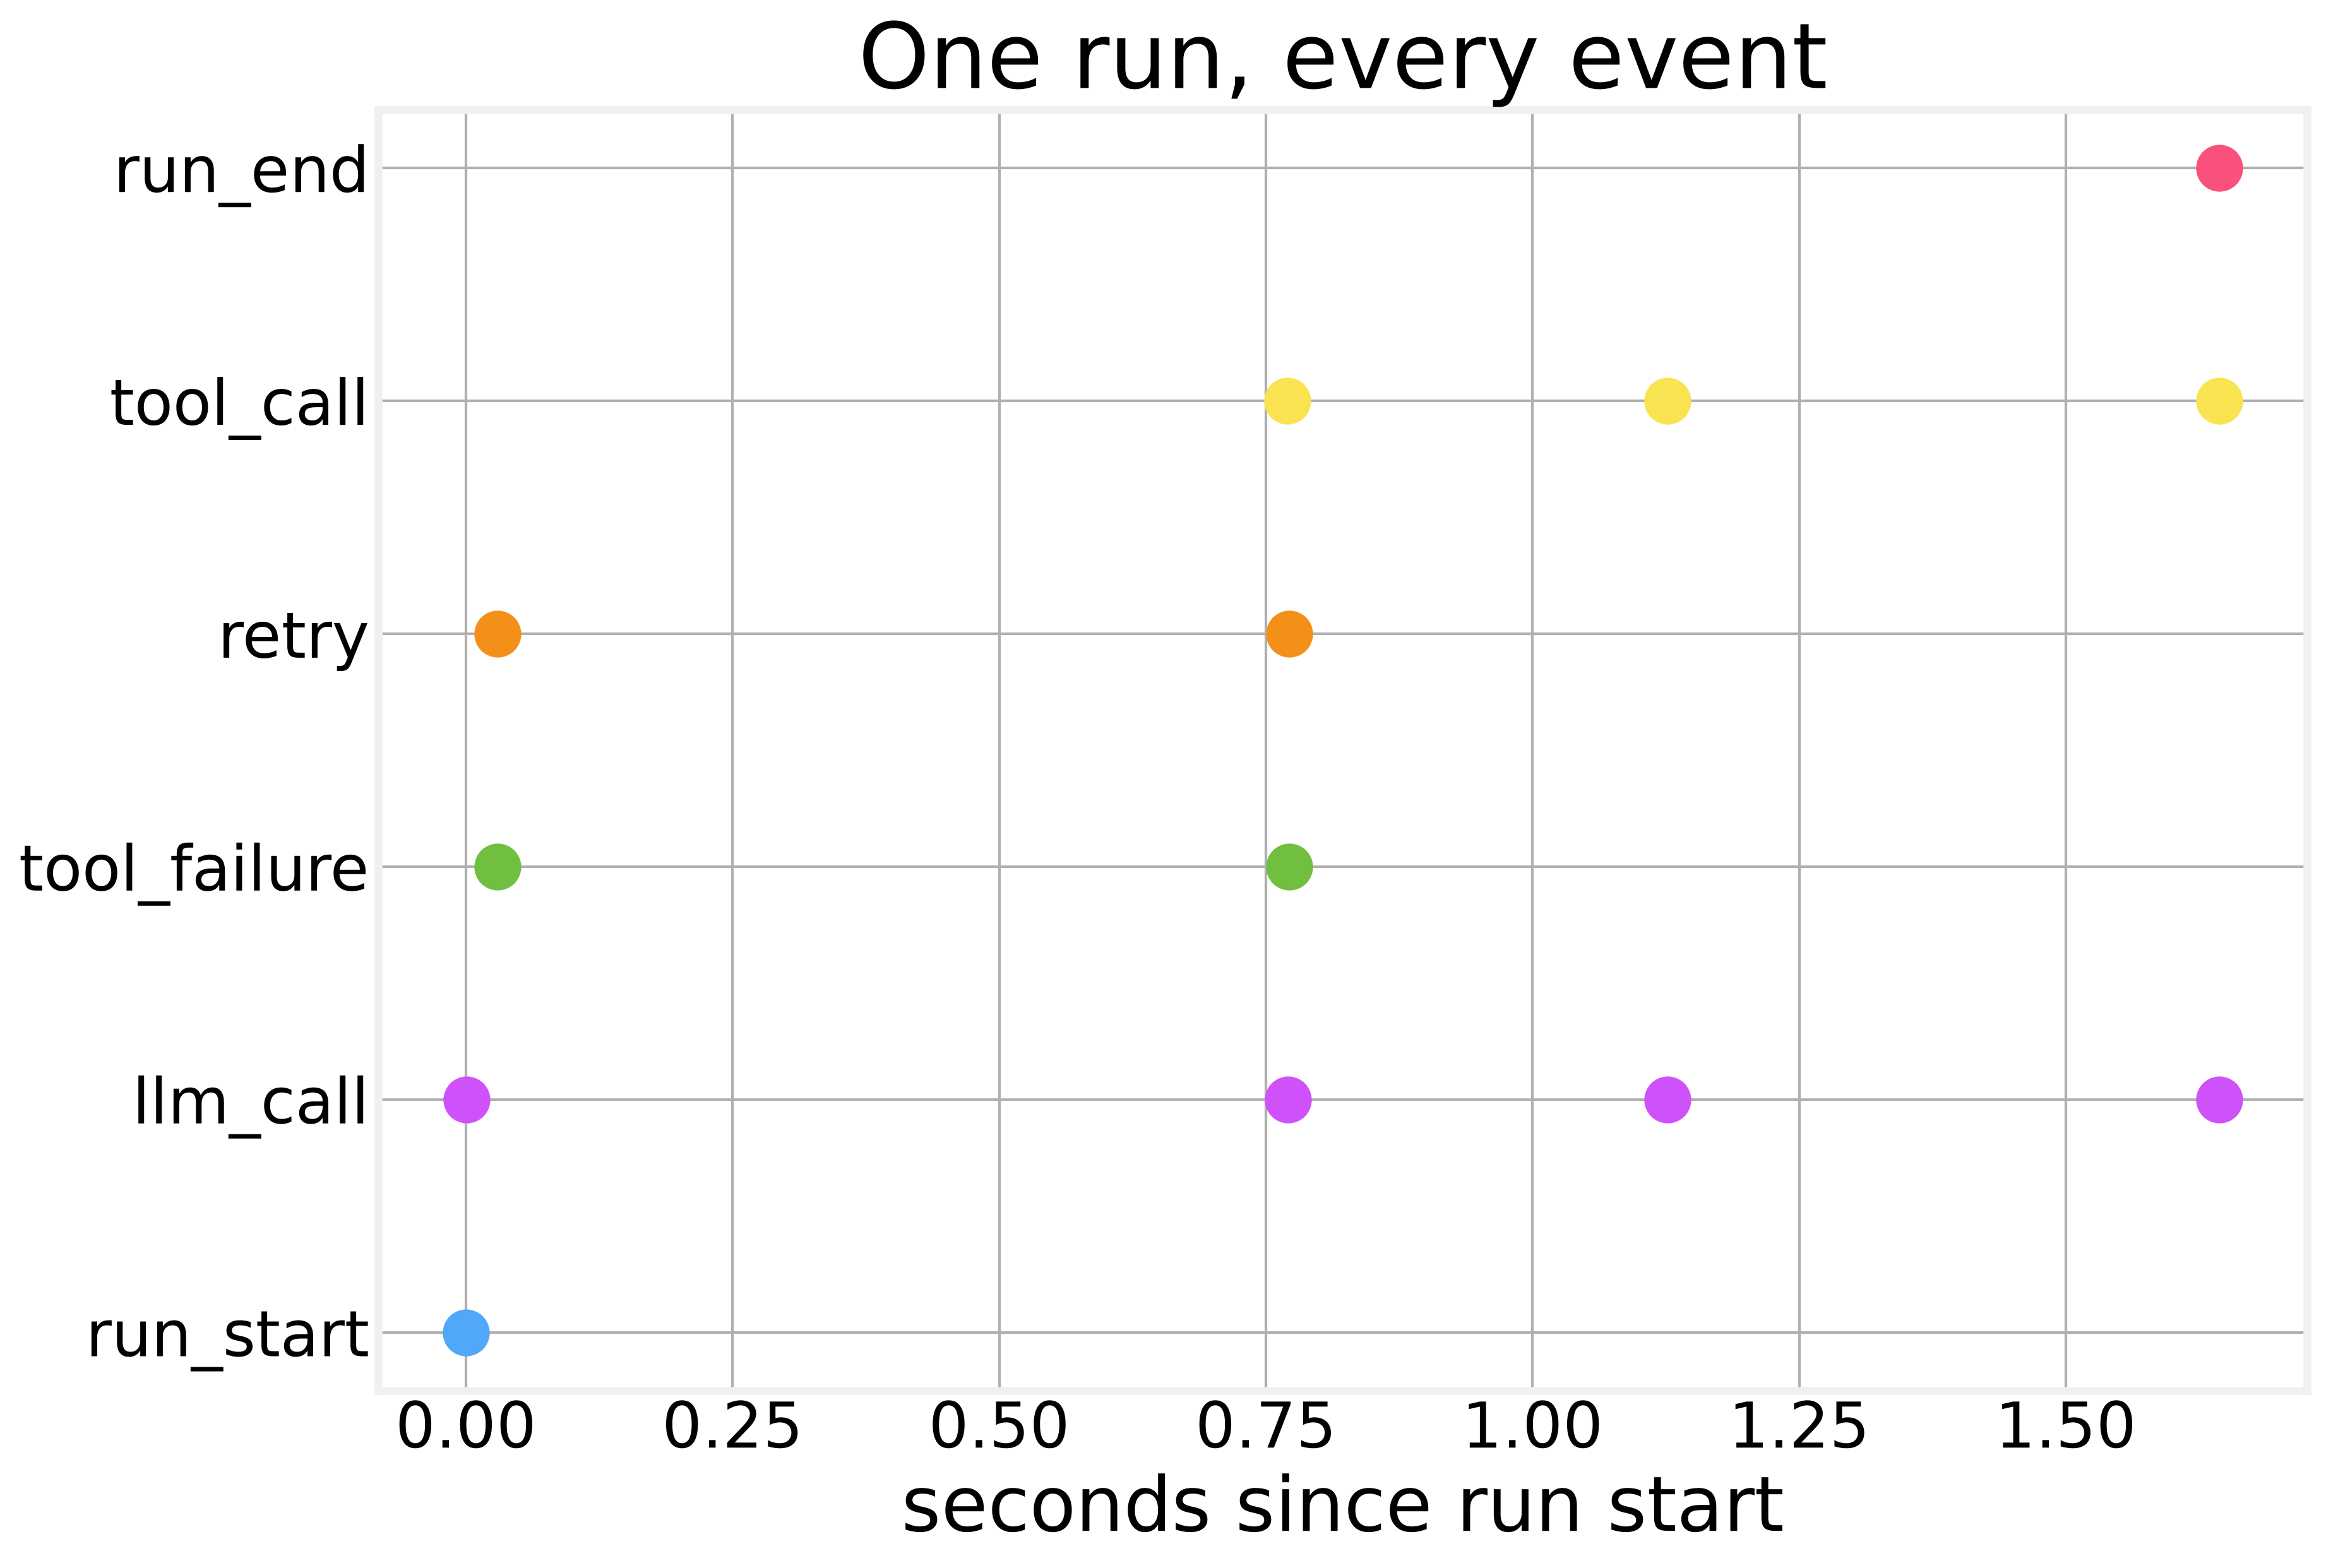

In [22]:
kinds = list(trace.kind.unique())
fig, ax = plt.subplots()
for i, kind in enumerate(kinds):
    ev = trace[trace.kind == kind]
    ax.scatter(ev.t, [i] * len(ev), s=300, color=colors[i % len(colors)])
ax.set_yticks(range(len(kinds)))
ax.set_yticklabels(kinds)
ax.set_xlabel("seconds since run start")
ax.set_title("One run, every event");

# 7. The scoreboard

The four questions from notebook 01, the same careless model, now inside the full harness:

In [23]:
QUESTIONS = {"monthly": "What was our monthly revenue in 2026?",
             "drop": "Why did revenue drop in August?",
             "feedback": "Summarize what customers said in their feedback in August.",
             "emea": EMEA}

rows = []
for key, q in QUESTIONS.items():
    h = build_analyst(MockAnalyst(context_window=10**6), client)
    res = h.run(q)
    statuses = Counter(c.status for c in h.verifier.last.checks)
    rows.append({"question": key, "status": res.status, "claims": sum(statuses.values()),
                 "verified": statuses["verified"],
                 "flagged": ", ".join(f"{k}:{v}" for k, v in statuses.items() if k != "verified"),
                 "blocked calls": sum(a["action"] != "allow" for a in h.gate.audit),
                 "injections quarantined": len(h.scanner.findings),
                 "tokens": res.input_tokens + res.output_tokens})
pd.DataFrame(rows)

,question,status,claims,verified,flagged,blocked calls,injections quarantined,tokens
0,monthly,completed,10,0,"unit_error:9, incomplete_period:1",0,0,3890
1,drop,completed,2,1,unsupported:1,0,0,1896
2,feedback,completed,2,2,,0,2,5009
3,emea,completed,3,0,"unit_error:2, incomplete_period:1",0,0,2003


The model still makes every mistake it made in notebook 01. The difference is that none of them reaches the user unannounced: wrong units, unsupported causes and incomplete periods are flagged, and the injection is quarantined before the model can act on it.

# 8. A fault matrix, then a test suite

Fault injection is most useful as a **regression suite**: every fault against every question, on every change to prompts, tools, policies or harness code.

In [24]:
matrix = {}
for fault in FAULTS:
    for key, q in QUESTIONS.items():
        h = build_analyst(MockAnalyst.careful(), client, fault_plan={1: fault, 3: fault})
        res = h.run(q)
        matrix[(fault, key)] = res.status
pd.Series(matrix).unstack()

,drop,emea,feedback,monthly
crash,completed,completed,completed,completed
malformed,completed,completed,completed,completed
oversized,completed,completed,completed,completed
permanent,completed,completed,completed,completed
slow,completed,completed,completed,completed
timeout,completed,completed,completed,completed
transient,completed,completed,completed,completed


The same checks live in `tests/test_faults.py`, a pytest suite that drives the real MCP server through the full harness while injecting faults. It also covers the injection, fabrication and missing-data scenarios. `tests/test_guardrails.py` holds the SQL attack corpus. The tests import **your** modules from `harness/`, so they check the harness you just built; any module that is missing is filled in from `reference/` (that's also how CI gets them, since the built modules are git-ignored).

In [25]:
print(Path("tests/test_faults.py").read_text()[:2200])

"""Fault-injected regression suite for the analyst harness.

Run with ``uv run pytest tests/``. Every test drives the real DuckDB MCP server
through the full harness while breaking something on purpose. In CI, run it on
every change to prompts, tools, policies or harness code.
"""

import os

import pytest

from harness.analyst import build_analyst
from harness.llm import MockAnalyst
from harness.supervisor import FAULTS, Budget

EMEA = "What was EMEA revenue in July compared to June?"
FEEDBACK = "Summarize what customers said in their feedback in August."
DROP = "Why did revenue drop in August?"


@pytest.mark.parametrize("fault", FAULTS)
def test_single_fault_is_survived(client, fault):
    h = build_analyst(MockAnalyst.careful(), client, fault_plan={1: fault})
    res = h.run(EMEA)
    assert res.status == "completed"
    assert res.answer.strip()
    assert h.faults.injected == [(1, fault)]


@pytest.mark.parametrize("fault", ["timeout", "transient", "malformed"])
def test_persiste

In [26]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests"], capture_output=True, text=True)
print(out.stdout[-600:])

.................................................................        [100%]
65 passed in 37.79s



To run it as a CI check on every pull request, add a workflow such as `.github/workflows/harness.yml`:

```yaml
name: harness
on: [pull_request]
jobs:
  faults:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: astral-sh/setup-uv@v6
      - run: uv sync
      - run: uv run pytest -q tests
```

No API keys and no GPU are needed: the mock model is deterministic and the database is generated on the fly. When you switch to a real model, keep this suite running against the mock as a fast gate, and add a slower scheduled job that runs the same scenarios against the real model and tracks pass rates over time.

**Takeaways**
- Classify every failure; only timeouts and transient errors deserve a retry.
- After a timeout, assume the server is in a bad state and restart it.
- Permanent errors go back to the model as precise messages, so it can re-plan.
- Budgets bound tokens, time and tool calls, and end runs cleanly.
- Trace everything as flat events; plots, logs and tests all come from the same data.
- Inject faults on purpose, in a test suite, on every change.

You now have the complete harness in `harness/`: `permissions`, `context`, `guardrails`, `verify`, `supervisor` and `analyst`, built by you on top of the agent loop, MCP client and mock model that came with the repo.

# Exercise: a circuit breaker

*Estimated time: 10 minutes*

Retries help when a failure is brief. When a dependency is **down**, retrying every call just piles more load on it and burns budget. A circuit breaker fails fast instead.

Write `CircuitBreaker(invoke, threshold=3, cooldown=5.0)`, a callable `(name, arguments) -> ToolResult` that wraps another invoker:

- **closed** (normal): pass calls through. Count consecutive failures (an exception **or** `ok=False`) and reset the count on success.
- after `threshold` consecutive failures it goes **open**: return `ToolResult(False, "circuit open: ...")` immediately, **without** calling the inner invoker.
- once `cooldown` seconds have passed, let **one** probe call through (*half-open*). If it succeeds, close the circuit; if it fails, open it again.
- never raise: exceptions become `ToolResult(ok=False, ...)`.

In [27]:
class CircuitBreaker:
    def __init__(self, invoke, threshold=3, cooldown=5.0):
        self.invoke = invoke
        # YOUR CODE HERE

    def __call__(self, name, arguments):
        # YOUR CODE HERE
        return self.invoke(name, arguments)

In [28]:
check_06(CircuitBreaker)

FAIL  never raises; failures come back as ToolResult(ok=False)  (connection reset (test))
FAIL  inner tool called only `threshold` times while open  (inner called 6 times)
FAIL  open circuit says so
PASS  after cooldown a probe call goes through
FAIL  a successful probe closes the circuit  (inner called 8 times)

Not there yet; keep going.


<details>
<summary><b>Show solution</b></summary>

```python
# Solution: a circuit breaker that fails fast after repeated failures.
import time

from harness.exercises import check_06
from harness.mcp_client import ToolResult


class CircuitBreaker:
    def __init__(self, invoke, threshold=3, cooldown=5.0):
        self.invoke = invoke
        self.threshold = threshold
        self.cooldown = cooldown
        self.failures = 0
        self.opened_at = None                       # None means closed

    def __call__(self, name, arguments):
        if self.opened_at is not None:
            if time.monotonic() - self.opened_at < self.cooldown:
                return ToolResult(False, f"circuit open: {name} failed {self.failures} times in a row; "
                                         "not calling it until the cooldown ends")
            # cooldown over: half-open, let one probe call through
        try:
            result = self.invoke(name, arguments)
        except Exception as e:  # noqa: BLE001
            result = ToolResult(False, f"{type(e).__name__}: {e}")
        if result.ok:
            self.failures, self.opened_at = 0, None
        else:
            self.failures += 1
            if self.failures >= self.threshold:
                self.opened_at = time.monotonic()
        return result


check_06(CircuitBreaker)
```

You can also load it into a new cell with `%load solutions/06_circuit_breaker.py`.

</details>

In [29]:
client.close()

<center>
     <img src="data/D4Sci_logo_full.png" alt="Data For Science, Inc" align="center" border="0" width=300px>
</center>